# Feature Engineering — Home Credit Credit Risk Model Stability

| Secao | Descricao |
|---|---|
| 1.0 | Selecao de Features e Mapeamento de Fontes |
| 2.0 | Processamento Depth 0 (Merges Estaticos) |
| 3.0 | Processamento Depth 1/2 (Agregacoes de Historico) |
| 4.0 | Criacao de Shadow Features |
| 5.0 | Engenharia de Features Avancada |
| 6.0 | Analise Categorica e One-Hot Encoding |
| 7.0 | Limpeza de Esparsidade e Imputacao |
| 8.0 | Diagnostico de Information Value (IV) |
| 9.0 | Divisao Temporal e Exportacao (OOT e Split 70/30) |
| 10.0 | Dicionario Tecnico das Features Final |

## 1.0 Seleção de Features e Mapeamento de Fontes

**Objetivo:** Reduzir o vasto espaço de dimensionalidade original (mais de 1.400 variáveis) para um núcleo com poucas colunas, vamos começar com 50 iniciais.

**Estratégia de Seleção:**

A seleção foi guiada por hipóteses qualitativas de risco de crédito, dividindo as variáveis nos seguintes grupos:

1. **Scores e Risco Externo:** O julgamento do mercado sobre o cliente (Bureau).
2. **Histórico de Atrasos (DPD - Days Past Due):** O melhor preditor de comportamento futuro é o comportamento passado.
3. **Endividamento e Montantes:** A capacidade financeira de suportar novas linhas de crédito (alavancagem).
4. **Rendimento e Emprego:** A estabilidade da geração de fluxo de caixa do cliente.
5. **Rejeições e Aplicações:** Sinais de "desespero" financeiro ou possíveis fraudes cibernéticas (múltiplas aplicações no mesmo IP/telemóvel).
6. **Contratos Anteriores:** Grau de maturidade e fidelidade com a instituição.

**Nota sobre a Arquitetura (Depth):**
* As variáveis marcadas como `(Depth 0)` são atributos estáticos e únicos por cliente no momento da decisão.
* As variáveis marcadas como `(Depth 1/2)` representam o histórico (ex: uma linha por cada prestação paga no passado). Estas variáveis exigem funções de agregação (`max`, `sum`, `mean`) para serem achatadas numa única linha por `case_id` antes do *merge* final.

In [29]:
# TOP 50 COLUNAS SELECIONADAS (ESTRITAMENTE PRÉ-DECISÃO / HISTÓRICAS)
colunas_selecionadas = [
    # ================= SCORES DE BUREAU (PRÉ-APROVAÇÃO) =================
    'score_940',                      # Score de crédito do bureau calculado ANTES desta aplicação.
    'riskassesment_302T',             # Avaliação de risco externa já existente no sistema.
    'riskassesment_940T',             # Segunda métrica de risco do bureau no momento da consulta.

    # ================= HISTÓRICO PASSADO DE ATRASOS (BUREAU) =================
    'maxdpdlast12m_727P',             # Maior atraso nos últimos 12 meses (histórico).
    'maxdpdlast24m_143P',             # Maior atraso nos últimos 24 meses (histórico).
    'avgdbddpdlast24m_3658932P',      # Média de dias de atraso nos últimos 2 anos.
    'maxdbddpdlast1m_3658939P',       # Atraso máximo detetado no mês anterior ao pedido de crédito.
    'pctinstlsallpaidlat10d_839L',    # % de prestações passadas pagas com >10 dias de atraso.
    'pctinstlsallpaidlate6d_3546844L',# % de prestações passadas pagas com >6 dias de atraso.
    'numinstlswithdpd5_4187116L',     # Número de prestações antigas com >5 dias de atraso.
    'actualdpd_943P',                 # DPD real registado num contrato de crédito ANTERIOR.
    'dpdmax_139P',                    # DPD máximo em créditos antigos ainda ativos no bureau.
    'dpdmax_757P',                    # DPD máximo em créditos antigos já encerrados.
    'pmts_dpd_1073P',                 # Consolidado de atrasos passados.

    # ================= ENDIVIDAMENTO PRÉ-EXISTENTE (NO MOMENTO DA APLICAÇÃO) =================
    # ATENÇÃO: Estas variáveis representam o que o cliente JÁ DEVIA
    # no mercado no momento exato em que preencheu a nova proposta de crédito.
    'totaldebt_9A',                   # Dívida total consolidada em outras instituições no dia do pedido.
    'currdebt_22A',                   # Saldo devedor pré-existente capturado na hora da análise.
    'totaldebtoverduevalue_178A',     # Montante em atraso financeiro de outros contratos ativos.
    'totaldebtoverduevalue_718A',     # Montante em atraso de contratos passados/fechados.
    'totaloutstanddebtvalue_39A',     # Dívida pendente de outros contratos (Bureau).
    'totaloutstanddebtvalue_668A',    # Dívida pendente de contratos fechados (Bureau).
    'debtoutstand_525A',              # Capital em dívida remanescente de contratos anteriores.
    'overdueamountmax_155A',          # Maior valor já registado em atraso no histórico do cliente.
    'overdueamountmax_35A',           # Maior valor em atraso em contratos encerrados.
    'residualamount_1093A',           # Saldo final a liquidar de dívidas passadas.
    'credamount_770A',                # Valor do crédito que está a ser SOLICITADO AGORA.
    'annuity_780A',                   # Valor da prestação proposta para o NOVO crédito.
    'amount_1115A',                   # Montantes de crédito antigo ativos no bureau.
    'credlmt_935A',                   # Limites de cartões de crédito que o cliente JÁ possui.
    'outstandingdebt_522A',           # Dívida pendente de empréstimos antigos.
    'monthlyinstlamount_332A',        # Custo mensal atual do cliente com outras prestações.
    'pmts_overdue_1140A',             # Valores históricos que ficaram em atraso.

    # ================= RENDIMENTO E PERFIL SÓCIO-ECONÓMICO =================
    'mainoccupationinc_384A',         # Rendimento principal declarado no ato da aplicação.
    'incometype_1044T',               # Tipo de rendimento (assalariado, pensionista, etc).
    'empl_employedfrom_271D',         # Data de início do emprego atual.
    'empl_employedtotal_800L',        # Tempo total de experiência profissional declarada.
    'commnoinclast6m_3546845L',       # Alerta de quebra de rendimento nos 6 meses anteriores à aplicação.
    'clientscnt_887L',                # Alerta de fraude: Quantos clientes usam o mesmo contacto/empregador.

    # ================= COMPORTAMENTO DE BUSCA E REJEIÇÕES PASSADAS =================
    'numrejects9m_859L',              # Quantas vezes o cliente foi rejeitado nos últimos 9 meses.
    'days30_165L',                    # Substituiu o texto da rejeição: Consultas ao bureau nos últimos 30 dias.
    'applicationscnt_867L',           # Consultas associadas ao mesmo telemóvel (alerta de fraude).
    'applicationscnt_629L',           # Consultas associadas ao mesmo empregador.
    'forquarter_462L',                # Consultas feitas ao bureau de crédito no trimestre anterior.
    'days180_256L',                   # Consultas feitas ao bureau nos últimos 180 dias.

    # ================= HISTÓRICO DE BONS PAGAMENTOS =================
    'numinstunpaidmaxest_4493212L',   # Prestações máximas não pagas em créditos antigos.
    'numinstpaid_4499208L',           # Número total de prestações antigas pagas com sucesso.
    'posfpd30lastmonth_3976960P',     # Se o cliente falhou a 1ª prestação noutro crédito no mês passado.
    'numactiverelcontr_750L',         # Quantidade de contratos (ex: cartões) ativamente em uso hoje.
    'pmtnum_8L',                      # Histórico de número de pagamentos efetuados.
    'tenor_203L',                     # Prazo original de empréstimos contratados no passado.
    'credacc_transactions_402L',      # Contagem de transações em contas de crédito anteriores.
]

print(f"Total de colunas selecionadas: {len(colunas_selecionadas)}")

Total de colunas selecionadas: 50


---

## 2.0 Processamento Depth 0 (Merges Estaticos)

Enriquecimento horizontal da `train_base` via LEFT JOIN com as tabelas estaticas do sistema interno (`train_static_0`) e do bureau de credito (`train_static_cb_0`). A auditoria confirma a preservacao rigorosa da granularidade original.

In [30]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
sys.path.append('/content/Projeto_06')

from utils_2 import (
    setup_environment,
    download_competition,
    get_table_groups,
    carregar_familia,
    downcast_train_base,
    merge_depth_0,
    descobrir_colunas_depth_1,
    merge_depth_1,
    analisar_valores_nulos,
    analisar_vif, 
    analisar_multicolinearidade_pares, 
    plot_matriz_correlacao
)
# Setup
PROJECT_ROOT = setup_environment()
base_dir = download_competition()
train_dir = base_dir / 'parquet_files' / 'train'
grupos_tabelas = get_table_groups(train_dir)

Ambiente configurado. Token Kaggle carregado.
Dados localizados em: /root/.cache/kagglehub/competitions/home-credit-credit-risk-model-stability
Foram mapeadas 17 familias de tabelas.


In [31]:
import pandas as pd

df_base = carregar_familia(grupos_tabelas, 'train_base')
df_base = downcast_train_base(df_base)

df_master = merge_depth_0(df_base, grupos_tabelas, colunas_selecionadas)
print(f"\nShape final Depth 0: {df_master.shape}")
display(df_master.head())

Carregando 'train_base' (1 arquivo(s))...
Carregando tabelas de Depth 0...
Carregando 'train_static_0' (2 arquivo(s))...
Carregando 'train_static_cb_0' (1 arquivo(s))...
Colunas em static_0: 20
Colunas em static_cb_0: 5

Auditoria Depth 0: 1,526,659 -> 1,526,659 linhas
Granularidade preservada. Shape: (1526659, 30)

Shape final Depth 0: (1526659, 30)


,case_id,date_decision,MONTH,WEEK_NUM,target,maxdpdlast12m_727P,maxdpdlast24m_143P,avgdbddpdlast24m_3658932P,maxdbddpdlast1m_3658939P,pctinstlsallpaidlat10d_839L,...,applicationscnt_629L,numinstunpaidmaxest_4493212L,numinstpaid_4499208L,posfpd30lastmonth_3976960P,numactiverelcontr_750L,riskassesment_302T,riskassesment_940T,days30_165L,forquarter_462L,days180_256L
0,0,2019-01-03,201901,0,0,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,1,2019-01-03,201901,0,0,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,2,2019-01-04,201901,0,0,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,3,2019-01-03,201901,0,0,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,4,2019-01-04,201901,0,1,0.0,0.0,NaN,NaN,NaN,...,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN


---

## 3.0 Processamento Depth 1/2 (Agregacoes de Historico)

Conversao de matrizes longitudinais (historico de prestacoes, transacoes, contratos) em vetores transversais por cliente via `groupby('case_id')`. Processamento em lote (Map-Reduce) com `gc.collect()` para mitigar risco de OOM.

In [32]:
agg_map_depth_1 = {
    # --- 1. Atrasos e Comportamento de Pagamento Passado ---
    'dpdmax_139P':                  ['max'],           # Pior atraso em contratos ainda ativos
    'dpdmax_757P':                  ['max'],           # Pior atraso em contratos já encerrados
    'pmts_dpd_1073P':               ['max', 'mean'],   # Pior atraso histórico e média de atrasos
    'pmts_overdue_1140A':           ['sum', 'max'],    # Volume financeiro total e máximo já atrasado
    'numinstunpaidmaxest_4493212L': ['max'],           # Pior cenário de prestações acumuladas sem pagamento
    'posfpd30lastmonth_3976960P':   ['max', 'mean'],   # Flag (max) e Taxa (mean) de falha na 1ª prestação (FPD)
    
    # --- 2. Endividamento e Limites Pré-existentes no Bureau ---
    'amount_1115A':                 ['sum', 'mean'],   # Exposição total e média em créditos ativos no bureau
    'credlmt_935A':                 ['sum', 'max'],    # Limites totais e limite máximo de cartões/linhas ativas
    'outstandingdebt_522A':         ['sum'],           # Saldo devedor total pendente no momento da análise
    'monthlyinstlamount_332A':      ['sum'],           # Custo total mensal com prestações que o cliente JÁ possui
    'numactiverelcontr_750L':       ['sum'],           # Total de contratos revogáveis (ex: cartões) ativos hoje
    
    # --- 3. Maturidade e Volume de Contratos Anteriores ---
    'credamount_770A':              ['sum', 'max'],    # Total de crédito solicitado no passado e maior ticket
    'annuity_780A':                 ['sum', 'mean'],   # Custo total e médio de anuidades anteriores
    'pmtnum_8L':                    ['sum', 'max'],    # Volume total de pagamentos já efetuados
    'numinstpaid_4499208L':         ['sum', 'mean'],   # Total de prestações pagas com sucesso
    'tenor_203L':                   ['mean', 'max'],   # Prazo original médio e máximo dos créditos antigos
    'credacc_transactions_402L':    ['sum', 'mean'],   # Volume total e médio de transações financeiras em contas
}
col_to_familia, familias = descobrir_colunas_depth_1(grupos_tabelas, agg_map=agg_map_depth_1)

df_master = merge_depth_1(df_master, grupos_tabelas, col_to_familia, familias, agg_map=agg_map_depth_1)
print(f"\nShape final Depth 1/2: {df_master.shape}")

Familias depth 1: ['train_applprev_1', 'train_credit_bureau_a_1', 'train_credit_bureau_a_2', 'train_credit_bureau_b_1']
Colunas mapeadas: 11 de 17
Ja na Depth 0 ou ausentes: ['numinstunpaidmaxest_4493212L', 'posfpd30lastmonth_3976960P', 'numactiverelcontr_750L', 'credamount_770A', 'annuity_780A', 'numinstpaid_4499208L']

-> train_applprev_1 (4 colunas, 2 arquivos)
  Shape agregado: (1221522, 8)

-> train_credit_bureau_a_1 (4 colunas, 4 arquivos)
  Shape agregado: (1386273, 6)

-> train_credit_bureau_a_2 (2 colunas, 11 arquivos)
  Shape agregado: (1385288, 5)

-> train_credit_bureau_b_1 (1 colunas, 1 arquivos)
  Shape agregado: (36500, 3)

Auditoria Depth 1: 1,526,659 -> 1,526,659 linhas
Colunas adicionadas: 18
Granularidade preservada. Shape: (1526659, 48)

Shape final Depth 1/2: (1526659, 48)


> **Total de Colunas** Veja que das 50 colunas que tentamos extrair, fechamos em 48 colunas.
>
> **Objetivo Atual** Analisar as colunas vazias e realizar engenharias de features

---

## 4.0 Criacao de Shadow Features

Extracao de poder preditivo do padrao de valores nulos. Flags binarias que capturam o perfil *Thin File* (cliente desconhecido pelo mercado) antes que as colunas ruidosas sejam descartadas.

In [33]:
import numpy as np

# Flag de presença de RiskAssessment 302T
if 'riskassesment_302T' in df_master.columns:
    df_master['Flag_Has_RiskAssessment_302T'] = (~df_master['riskassesment_302T'].isna()).astype('int8')

# Flag de presença de RiskAssessment 940T
if 'riskassesment_940T' in df_master.columns:
    df_master['Flag_Has_RiskAssessment_940T'] = (~df_master['riskassesment_940T'].isna()).astype('int8')

# Flag Thin File: sem nenhum dos dois scores de bureau
cols_bureau = [c for c in ['riskassesment_302T', 'riskassesment_940T'] if c in df_master.columns]
if len(cols_bureau) == 2:
    df_master['Flag_Thin_File'] = (
        df_master[cols_bureau[0]].isna() & df_master[cols_bureau[1]].isna()
    ).astype('int8')
elif len(cols_bureau) == 1:
    df_master['Flag_Thin_File'] = df_master[cols_bureau[0]].isna().astype('int8')

shadow_cols = ['Flag_Has_RiskAssessment_302T', 'Flag_Has_RiskAssessment_940T', 'Flag_Thin_File']
for c in shadow_cols:
    if c in df_master.columns:
        print(f"{c}: {df_master[c].sum():,} positivos ({df_master[c].mean()*100:.2f}%)")

print(f"\nShape após shadow features: {df_master.shape}")

Flag_Has_RiskAssessment_302T: 53,559 positivos (3.51%)
Flag_Has_RiskAssessment_940T: 53,560 positivos (3.51%)
Flag_Thin_File: 1,473,099 positivos (96.49%)

Shape após shadow features: (1526659, 51)


---

## 5.0 Engenharia de Features Avancada

Sintese de conhecimento de negocio em variaveis cruzadas (interacoes de 2a ordem) organizadas em cinco eixos preditivos: Racios de Esforco, Dinamica de Atrasos, Intensidade de Busca, Flags de Risco Critico e Contexto Macroeconomico.

### 5.1 Racios de Alavancagem e Esforco Financeiro

**Objetivo:** Medir a proporcao do endividamento e o peso que uma nova linha de credito exerce sobre a capacidade financeira do cliente. Em vez de olhar para valores absolutos, os racios normalizam o risco.

**Tratamento de divisao por zero:** Os racios utilizam `np.where` para preservar os valores reais. Onde o divisor for zero ou nulo, o resultado e `NaN` (e nao um valor artificial como `+ 1`). Isto aproveita o tratamento nativo de NaNs dos algoritmos de Boosting (LightGBM, CatBoost, XGBoost), que encaminham observacoes com missing values para ramos dedicados na arvore de decisao.

**Features Criadas:**
* **`Racio_Anuidade_Credito`**: `np.where(credamount_770A > 0, annuity_780A / credamount_770A, NaN)`. Peso da amortizacao sobre o credito total. Valores altos indicam credito de curto prazo ou predatorio.
* **`Taxa_Utilizacao_Global`**: `np.where(credlmt_935A_sum > 0, currdebt_22A / credlmt_935A_sum, NaN)`. Saturacao das linhas de credito. Clientes proximos de 1.0 estao sem margem financeira.
* **`Severidade_Divida_Vencida`**: `np.where(totaldebt_9A > 0, totaldebtoverduevalue_178A / totaldebt_9A, NaN)`. Percentagem da divida em atraso formal.
* **`Ticket_Medio_Historico`**: `np.where(pmtnum_8L_sum > 0, monthlyinstlamount_332A_sum / pmtnum_8L_sum, NaN)`. Valor medio que o cliente suporta pagar mensalmente.
* **`Endividamento_vs_Rendimento`**: `np.where(mainoccupationinc_384A > 0, currdebt_22A / mainoccupationinc_384A, NaN)`. Grau de comprometimento da renda (DTI).

In [34]:
# --- Ratios ---

# Rácio Anuidade vs Crédito: anuidade / limite de crédito
if 'annuity_780A' in df_master.columns and 'credamount_770A' in df_master.columns:
    df_master['Racio_Anuidade_Credito'] = df_master['Racio_Anuidade_Credito'] = np.where(
    df_master['credamount_770A'].fillna(0) > 0, 
    df_master['annuity_780A'] / df_master['credamount_770A'], 
    np.nan
).astype('float32')

# Taxa de Utilização Global: dívida atual / limite total
if 'currdebt_22A' in df_master.columns and 'credlmt_935A_sum' in df_master.columns:
    df_master['Taxa_Utilizacao_Global'] = np.where(
        df_master['credlmt_935A_sum'].fillna(0) > 0,
        df_master['currdebt_22A'] / (df_master['credlmt_935A_sum'].fillna(0) + 1),
        np.nan
    ).astype('float32')

# Severidade da Dívida Vencida: dívida vencida / dívida total
if 'totaldebtoverduevalue_178A' in df_master.columns and 'totaldebt_9A' in df_master.columns:
    df_master['Severidade_Divida_Vencida'] = np.where(
        df_master['totaldebt_9A'].fillna(0) > 0,
        df_master['totaldebtoverduevalue_178A'] / (df_master['totaldebt_9A'].fillna(0) + 1),
        np.nan
    ).astype('float32')

# Ticket Médio Histórico: montante médio por prestação
if 'monthlyinstlamount_332A_sum' in df_master.columns and 'pmtnum_8L_sum' in df_master.columns:
    df_master['Ticket_Medio_Historico'] = np.where(
        df_master['pmtnum_8L_sum'].fillna(0) > 0,
        df_master['monthlyinstlamount_332A_sum'].fillna(0) / (df_master['pmtnum_8L_sum'].fillna(0) + 1),
        np.nan
    ).astype('float32')

# Endividamento vs Rendimento: dívida atual / rendimento principal
if 'currdebt_22A' in df_master.columns and 'mainoccupationinc_384A' in df_master.columns:
    df_master['Endividamento_vs_Rendimento'] = np.where(
        df_master['mainoccupationinc_384A'].fillna(0) > 0,
        df_master['currdebt_22A'] / (df_master['mainoccupationinc_384A'].fillna(0) + 1),
        np.nan
    ).astype('float32')

print("Ratios criadas.")

Ratios criadas.


### 5.2 Dinâmica de Atrasos (DPD Momentum)

**Objetivo:** Capturar a tendência temporal do comportamento de pagamentos, sinalizando se o cliente está a recuperar ou a entrar numa espiral de degradação recente.

**Features Criadas:**
* **`Aceleracao_Atraso_Ativo`**: (DPD Atual - DPD Máximo 24m). Valores positivos indicam que o atraso atual é o pior registado nos últimos 2 anos (sinal agudo de degradação).
* **`Flag_Pico_Atraso_Recente`**: (1/0 se DPD Atual > Mediana Histórica). Marca clientes cujo atraso no presente destoa negativamente do seu comportamento típico.
* **`Racio_Falhas_Prestracoes`**: (Prestações com DPD > 0 / Prestações Pagas). A taxa histórica de "falhas" e deslizes nos pagamentos.
* **`Diferencial_Degradacao_Cliente`**: (DPD Máximo 12m - DPD Máximo 24m). Compara o pior atraso do último ano com o pior atraso do ano anterior para identificar a evolução da disciplina financeira.

In [35]:
# --- Dinâmica de DPD ---

# Aceleração de Atraso Ativo: DPD atual vs máximo histórico
if 'actualdpd_943P' in df_master.columns and 'maxdpdlast24m_143P' in df_master.columns:
    df_master['Aceleracao_Atraso_Ativo'] = (
        df_master['actualdpd_943P'].fillna(0) - df_master['maxdpdlast24m_143P'].fillna(0)
    ).astype('float32')

# Flag Pico de Atraso Recente: DPD atual > mediana dos máximos
if 'actualdpd_943P' in df_master.columns:
    mediana_dpd = df_master['actualdpd_943P'].median()
    df_master['Flag_Pico_Atraso_Recente'] = (
        df_master['actualdpd_943P'].fillna(0) > mediana_dpd
    ).astype('int8')

# Rácio de Falhas em Prestações: inst. com DPD > 0 / total inst.
if 'numinstlswithdpd5_4187116L' in df_master.columns and 'numinstpaid_4499208L' in df_master.columns:
    df_master['Racio_Falhas_Prestracoes'] = (
        df_master['numinstlswithdpd5_4187116L'] / (df_master['numinstpaid_4499208L'].fillna(0) + 1)
    ).astype('float32')

# Diferencial de Degradação do Cliente: DPD 12m vs 24m
if 'maxdpdlast12m_727P' in df_master.columns and 'maxdpdlast24m_143P' in df_master.columns:
    df_master['Diferencial_Degradacao_Cliente'] = (
        df_master['maxdpdlast12m_727P'].fillna(0) - df_master['maxdpdlast24m_143P'].fillna(0)
    ).astype('float32')

print("Dinâmica de DPD criada.")

Dinâmica de DPD criada.


### 5.3 Intensidade de Busca e Sinais Anómalos

**Objetivo:** Identificar urgência financeira, "desespero" por crédito e anomalias sistémicas que costumam estar associadas a fraude cibernética ou falsidade ideológica.

**Features Criadas:**
* **`Frequencia_Rejeicoes_Mensal`**: A taxa mensal de negações de crédito pelo mercado. Alta frequência denota cliente altamente rejeitado.
* **`Termometro_Busca_Bureau`**: (Aplicações mesmo usuário) Mede distorções nos pedidos. Um alto volume de pedidos do mesmo usuário pode indicar fraude.
* **`Probabilidade_Rendimento_Instavel`**: Variação absoluta entre a renda declarada e o alerta de ausência de renda nos últimos 6 meses. Sinaliza trabalhadores com instabilidade laboral.

In [36]:
# --- Intensidade ---

# Frequência de Rejeições Mensal: rejeições / meses de janela
if 'numrejects9m_859L' in df_master.columns:
    df_master['Frequencia_Rejeicoes_Mensal'] = (
        df_master['numrejects9m_859L'].fillna(0) / 9
    ).astype('float32')

# Termômetro de Busca no Bureau: aplicações recentes normalizadas
if 'applicationscnt_867L' in df_master.columns and 'applicationscnt_629L' in df_master.columns:
    df_master['Termometro_Busca_Bureau'] = (
        df_master['applicationscnt_867L'].fillna(0) / (df_master['applicationscnt_629L'].fillna(0) + 1)
    ).astype('float32')

# Probabilidade de Rendimento Instável: variação entre fontes de rendimento
if 'mainoccupationinc_384A' in df_master.columns and 'commnoinclast6m_3546845L' in df_master.columns:
    df_master['Probabilidade_Rendimento_Instavel'] = (
        (df_master['mainoccupationinc_384A'].fillna(0) - df_master['commnoinclast6m_3546845L'].fillna(0)).abs()
        / (df_master['mainoccupationinc_384A'].fillna(0) + 1)
    ).astype('float32')

print("Intensidade criada.")

Intensidade criada.


### 5.4 Flags Binários de Risco Crítico

**Objetivo:** Isolar comportamentos extremos que, de forma isolada, já determinam uma probabilidade muito alta de inadimplência (default).

**Features Criadas:**
* **`Flag_First_Payment_Default`**: (1/0 se FPD > 0). Indica se o cliente falhou logo o primeiro pagamento de um contrato anterior. Este é o mais forte indício de fraude intencional (o chamado perfil *never pay*).
* **`Flag_Sobre_Endividamento_Aberto`**: (1/0 se Dívida > 80% do Limite). Marca duramente os clientes que já operam acima do teto saudável de segurança financeira estipulado pelas instituições.

In [37]:
# (Nome real da coluna de Depth 0 é sem o sufixo '_max')
col_fpd = 'posfpd30lastmonth_3976960P'
if col_fpd in df_master.columns:
    df_master['Flag_First_Payment_Default'] = (
        df_master[col_fpd].fillna(0) > 0
    ).astype('int8')
    print(f"Flag_First_Payment_Default criado: {df_master['Flag_First_Payment_Default'].sum():,} positivos")

# 2. Sobre-endividamento Aberto: dívida atual > 80% do limite total consolidado
# (Usa o limite consolidado 'credlmt_935A_sum' gerado no Depth 1)
col_limite = 'credlmt_935A_sum'
if 'currdebt_22A' in df_master.columns and col_limite in df_master.columns:
    divida = df_master['currdebt_22A'].fillna(0)
    limite = df_master[col_limite].fillna(0)
    
    # Marcamos 1 se a dívida superar 80% do limite (e houver limite positivo)
    df_master['Flag_Sobre_Endividamento_Aberto'] = (
        (limite > 0) & (divida > 0.8 * limite)
    ).astype('int8')
    print(f"Flag_Sobre_Endividamento_Aberto criado: {df_master['Flag_Sobre_Endividamento_Aberto'].sum():,} positivos")

Flag_First_Payment_Default criado: 11,227 positivos
Flag_Sobre_Endividamento_Aberto criado: 73,978 positivos


### 5.5 Features Avancadas, Sazonais e Macroeconomicas

**Objetivo:** Normalizar o perfil de risco do cliente de acordo com o ambiente externo (contexto temporal, impacto de crises sistemicas e a sua classe socioeconomica).

**Features Criadas:**
* **`Mes_do_Ano`**: Extraido da data de decisao (`MONTH % 100`). Transformado em `category` e submetido a One-Hot Encoding com `drop_first=True`, gerando variaveis dummy de `Mes_do_Ano_2` a `Mes_do_Ano_12` (janeiro como referencia). Permite ao modelo aprender a ciclicidade natural do consumo e inadimplencia.
* **`Flag_Pandemia`**: (1/0 a partir de Marco de 2020). Isola o choque sistemico provocado pela COVID-19, criando dois regimes de avaliacao para o algoritmo de Machine Learning.
* **`Rendimento_vs_Media_Profissao`**: (Rendimento do Cliente / Rendimento Medio da Profissao). Posicionamento relativo. Descobre se o cliente tem um salario acima ou abaixo dos seus pares.
* **`Divida_vs_Media_Profissao`**: (Divida do Cliente / Divida Media da Profissao). Sinaliza endividamento anomalo dentro de uma mesma classe social.
* **`Volatilidade_Divida_Vencida`**: (Desvio Padrao do Overdue). Avalia se os valores que o cliente deixa em atraso sao constantes ou muito instaveis.
* **`Stress_Nova_Prestacao`**: Racio de esforco ponderado em 50% pelo Flag da Pandemia. Simula a pressao adicional exercida por uma nova anuidade durante um periodo de crise severa.

In [38]:
# --- Features Avançadas ---

# Mês do Ano (ciclicidade sazonal)
if 'MONTH' in df_master.columns:
    df_master['Mes_do_Ano'] = (df_master['MONTH'] % 100).astype('int16')

# Flag Pandemia (março 2020 em diante)
if 'MONTH' in df_master.columns:
    df_master['Flag_Pandemia'] = (df_master['MONTH'] >= 202003).astype('int8')

# Rendimento vs Média da Profissão
if 'mainoccupationinc_384A' in df_master.columns and 'incometype_1044T' in df_master.columns:
    media_prof = df_master.groupby('incometype_1044T')['mainoccupationinc_384A'].transform('mean')
    df_master['Rendimento_vs_Media_Profissao'] = (
        df_master['mainoccupationinc_384A'].fillna(0) / (media_prof.fillna(0) + 1)
    ).astype('float32')

# Dívida vs Média da Profissão
if 'currdebt_22A' in df_master.columns and 'incometype_1044T' in df_master.columns:
    media_div_prof = df_master.groupby('incometype_1044T')['currdebt_22A'].transform('mean')
    df_master['Divida_vs_Media_Profissao'] = (
        df_master['currdebt_22A'].fillna(0) / (media_div_prof.fillna(0) + 1)
    ).astype('float32')

# Volatilidade da Dívida Vencida (desvio padrão do overdue ao longo do histórico)
overdue_cols = [c for c in df_master.columns if 'totaldebtoverduevalue' in c]
if len(overdue_cols) >= 2:
    df_master['Volatilidade_Divida_Vencida'] = df_master[overdue_cols].std(axis=1).astype('float32')

# Stress Nova Prestação: anuidade relativa ao rendimento, ponderada por pandemia
if 'annuity_780A' in df_master.columns and 'mainoccupationinc_384A' in df_master.columns and 'Flag_Pandemia' in df_master.columns:
    df_master['Stress_Nova_Prestacao'] = (
        (df_master['annuity_780A'].fillna(0) / (df_master['mainoccupationinc_384A'].fillna(0) + 1))
        * (1 + df_master['Flag_Pandemia'] * 0.5)
    ).astype('float32')

print("Features avançadas criadas.")
print(f"\nShape final após engenharia: {df_master.shape}")
print(f"Colunas totais: {df_master.shape[1]}")

Features avançadas criadas.

Shape final após engenharia: (1526659, 62)
Colunas totais: 62


### 5.6 Diagnostico de Nulos Pos-Engenharia

Identificacao de colunas com esparsidade excessiva gerada pelos merges Depth 1/2, antes da limpeza formal.

In [39]:
analisar_valores_nulos(df_master, plotar=False, figsize=(14, 6))

,Total Nulos,Percentual (%),Tipo de Dado
amount_1115A_mean,1501222,98.333813,float32
amount_1115A_sum,1490159,97.609158,float32
forquarter_462L,1490145,97.608241,float64
riskassesment_302T,1473100,96.491751,object
riskassesment_940T,1473099,96.491685,float64
credacc_transactions_402L_mean,1273086,83.390331,float32
maxdbddpdlast1m_3658939P,960953,62.944836,float64
Taxa_Utilizacao_Global,874895,57.307821,float32
numinstpaid_4499208L,847191,55.493139,float64
numinstunpaidmaxest_4493212L,840646,55.064425,float64


---

## 6.0 Analise Categorica e One-Hot Encoding

Identificacao de variaveis `object`/categoricas, analise de cardinalidade e concentracao na moda. Descarte de identificadores anonimizados e aplicacao de OHE quando ha sinal real.

> **Descarte forcado:** a coluna `lastrejectreasonclient_4145040M` e um codigo anonimizado de altissima cardinalidade que nao agrega poder discriminativo. Sua presenca gera ruido e dimensionalidade espuria, sendo removida explicitamente antes da limpeza de esparsidade.

In [40]:
# Colunas a ser transformadas em categóricas

df_master['Mes_do_Ano'] = df_master['Mes_do_Ano'].astype('category') #será feito onehot nela


In [ ]:
import pandas as pd
import numpy as np

# 6.1 Remocao explicita de identificador anonimizado
if 'lastrejectreasonclient_4145040M' in df_master.columns:
    df_master = df_master.drop(columns=['lastrejectreasonclient_4145040M'])
    print('Removida: lastrejectreasonclient_4145040M (codigo anonimizado, ruido de alta cardinalidade)')

# 6.2 Identificar colunas object/categoricas remanescentes
cat_cols = df_master.select_dtypes(include=['object', 'category']).columns.tolist()
print(f'\nColunas categoricas encontradas: {len(cat_cols)}')
for c in cat_cols:
    print(f'  {c}')

# Descarte forçado de colunas textuais com extrema esparsidade
cols_esparsas = [c for c in cat_cols if df_master[c].isna().mean() > 0.90]
if cols_esparsas:
    df_master = df_master.drop(columns=cols_esparsas)
    # CORREÇÃO: Atualizar a lista de colunas categóricas para o próximo loop
    cat_cols = [c for c in cat_cols if c not in cols_esparsas] 
    print(f"Descartadas por extrema esparsidade (>90%): {cols_esparsas}")

# 6.3 Diagnostico de cardinalidade e concentracao na moda
diag_rows = []
for col in cat_cols:
    nunique = df_master[col].nunique()
    n_nulls = df_master[col].isna().sum()
    pct_nulls = n_nulls / len(df_master) * 100
    mode_val = df_master[col].mode().iloc[0] if not df_master[col].mode().empty else None
    mode_count = (df_master[col] == mode_val).sum() if mode_val is not None else 0
    mode_pct = mode_count / len(df_master) * 100
    diag_rows.append({
        'Coluna': col,
        'Cardinalidade': nunique,
        'Nulos': n_nulls,
        '% Nulos': round(pct_nulls, 2),
        'Moda': str(mode_val),
        'Concentracao Moda (%)': round(mode_pct, 2)
    })

df_diag = pd.DataFrame(diag_rows)
if not df_diag.empty:
    display(df_diag)

# 6.4 Aplicacao de criterios de descarte e OHE
THRESHOLD_CONCENTRACAO = 90.0
THRESHOLD_CARDINALIDADE_OHE = 20

cols_descartar = []
cols_ohe = []

for _, row in df_diag.iterrows():
    col = row['Coluna']
    if row['Concentracao Moda (%)'] > THRESHOLD_CONCENTRACAO:
        cols_descartar.append(col)
        print(f'  DESCARTE (concentracao {row["Concentracao Moda (%)"]:.1f}%): {col}')
    elif row['Cardinalidade'] <= THRESHOLD_CARDINALIDADE_OHE:
        cols_ohe.append(col)
        print(f'  OHE CANDIDATO (card={row["Cardinalidade"]}): {col}')
    else:
        cols_descartar.append(col)
        print(f'  DESCARTE (cardinalidade alta): {col}')

cols_descartar_existentes = [c for c in cols_descartar if c in df_master.columns]
if cols_descartar_existentes:
    df_master = df_master.drop(columns=cols_descartar_existentes)
    print(f'\n{len(cols_descartar_existentes)} colunas descartadas.')

cols_ohe_existentes = [c for c in cols_ohe if c in df_master.columns]
if cols_ohe_existentes:
    df_ohe = pd.get_dummies(df_master[cols_ohe_existentes], drop_first=True, dtype='int8')
    df_master = pd.concat([df_master.drop(columns=cols_ohe_existentes), df_ohe], axis=1)
    print(f'{len(cols_ohe_existentes)} colunas convertidas via OHE.')
else:
    print('\nNenhuma coluna candidata a OHE passou no criterio.')

remaining_obj = df_master.select_dtypes(include=['object']).columns.tolist()
if not remaining_obj:
    print(f'Base 100% numerica. Shape: {df_master.shape}')
else:
    print(f'AVISO: colunas object remanescentes: {remaining_obj}')


Colunas categoricas encontradas: 2
  riskassesment_302T
  Mes_do_Ano
Descartadas por extrema esparsidade (>90%): ['riskassesment_302T']


,Coluna,Cardinalidade,Nulos,% Nulos,Moda,Concentracao Moda (%)
0,Mes_do_Ano,12,0,0.0,1,10.63


  OHE CANDIDATO (card=12): Mes_do_Ano
1 colunas convertidas via OHE.
Base 100% numerica. Shape: (1526659, 71)


> **Conclusao:** Apos remocao forcada do identificador anonimizado e aplicacao dos criterios de concentracao na moda (>90%) e cardinalidade, a base deve conter apenas variaveis numericas. A coluna `incometype_1044T` (categoria de rendimento) sera avaliada para OHE se sua cardinalidade for baixa e a concentracao na moda inferior a 90%.

---

## 7.0 Limpeza de Esparsidade e Imputacao

Remocao de variaveis com esparsidade extrema e imputacao estrategica baseada na semantica da variavel. A distincao entre **zero logico** (ausencia = zero eventos) e **NaN preditivo** (ausencia = cliente desconhecido) e critica para modelos de Gradient Boosting.

> **Racional 0 vs NaN:** colunas de contagem (número de rejeições, aplicações, contratos) recebem 0 quando nulas, pois a ausência do registo equivale a zero eventos. Colunas de DPD e histórico de pagamentos preservam NaN porque a ausência indica que o cliente não possui histórico no bureau -- informação distinta de "DPD = 0".

### 7.1 Remocao de Features com mais de 70% Nulos 

In [42]:
# 6.1 Remover colunas com >70% de nulos
pct_nulos = df_master.isnull().mean()
cols_remover = pct_nulos[pct_nulos > 0.70].index.tolist()
print(f"Colunas com >70% de nulos ({len(cols_remover)}):")
for c in cols_remover:
    print(f"  {c}: {pct_nulos[c]*100:.1f}%")

df_master = df_master.drop(columns=cols_remover)
print(f"\nShape após remoção: {df_master.shape}")

Colunas com >70% de nulos (5):
  riskassesment_940T: 96.5%
  forquarter_462L: 97.6%
  credacc_transactions_402L_mean: 83.4%
  amount_1115A_sum: 97.6%
  amount_1115A_mean: 98.3%

Shape após remoção: (1526659, 66)


### 7.2 Imputacao de Nulos

- Alguns NaN como flags/contagens/etc podem ser imputados diretos no dataset, outros dependerá do modelo de predição com o uso de Pipelines

In [43]:
# 6.2 Imputação zero lógico para colunas de contagem/flag
colunas_zero_logico = [
    # Flags e contagens de bureau
    'numrejects9m_859L', 'applicationscnt_867L', 'applicationscnt_629L',
    'forquarter_462L', 'days180_256L', 'clientscnt_887L',
    'empl_employedtotal_800L',
    # Contagens de contratos
    'numinstunpaidmaxest_4493212L', 'numinstpaid_4499208L', 'numinstlswithdpd5_4187116L',
    'numactiverelcontr_750L', 'pmtnum_8L_max', 'pmtnum_8L_sum',
    'credacc_transactions_402L_sum', 'credacc_transactions_402L_mean',
    # Flags criados
    'Flag_Has_RiskAssessment_302T', 'Flag_Has_RiskAssessment_940T',
    'Flag_Thin_File', 'Flag_First_Payment_Default',
    'Flag_Sobre_Endividamento_Aberto', 'Flag_Pico_Atraso_Recente',
    'Flag_Pandemia',
]

for col in colunas_zero_logico:
    if col in df_master.columns:
        nulos_antes = df_master[col].isna().sum()
        df_master[col] = df_master[col].fillna(0)
        if nulos_antes > 0:
            print(f"  {col}: {nulos_antes:,} nulos imputados como 0")

print("\nImputação zero lógico concluída.")

  days180_256L: 140,968 nulos imputados como 0
  numinstunpaidmaxest_4493212L: 840,646 nulos imputados como 0
  numinstpaid_4499208L: 847,191 nulos imputados como 0
  numinstlswithdpd5_4187116L: 561,124 nulos imputados como 0
  pmtnum_8L_max: 321,446 nulos imputados como 0
  pmtnum_8L_sum: 305,137 nulos imputados como 0
  credacc_transactions_402L_sum: 305,137 nulos imputados como 0

Imputação zero lógico concluída.


### 7.3 Analise de Nulos Residuais

NaN remanescentes em colunas de DPD/Overdue (preservados):
  maxdpdlast12m_727P: 306,019 NaN (20.0%)
  maxdpdlast24m_143P: 306,019 NaN (20.0%)
  avgdbddpdlast24m_3658932P: 613,202 NaN (40.2%)
  maxdbddpdlast1m_3658939P: 960,953 NaN (62.9%)
  dpdmax_139P_max: 263,166 NaN (17.2%)
  dpdmax_757P_max: 514,070 NaN (33.7%)
  pmts_dpd_1073P_max: 263,166 NaN (17.2%)
  pmts_dpd_1073P_mean: 263,166 NaN (17.2%)
  pmts_overdue_1140A_sum: 141,371 NaN (9.3%)
  pmts_overdue_1140A_max: 262,653 NaN (17.2%)


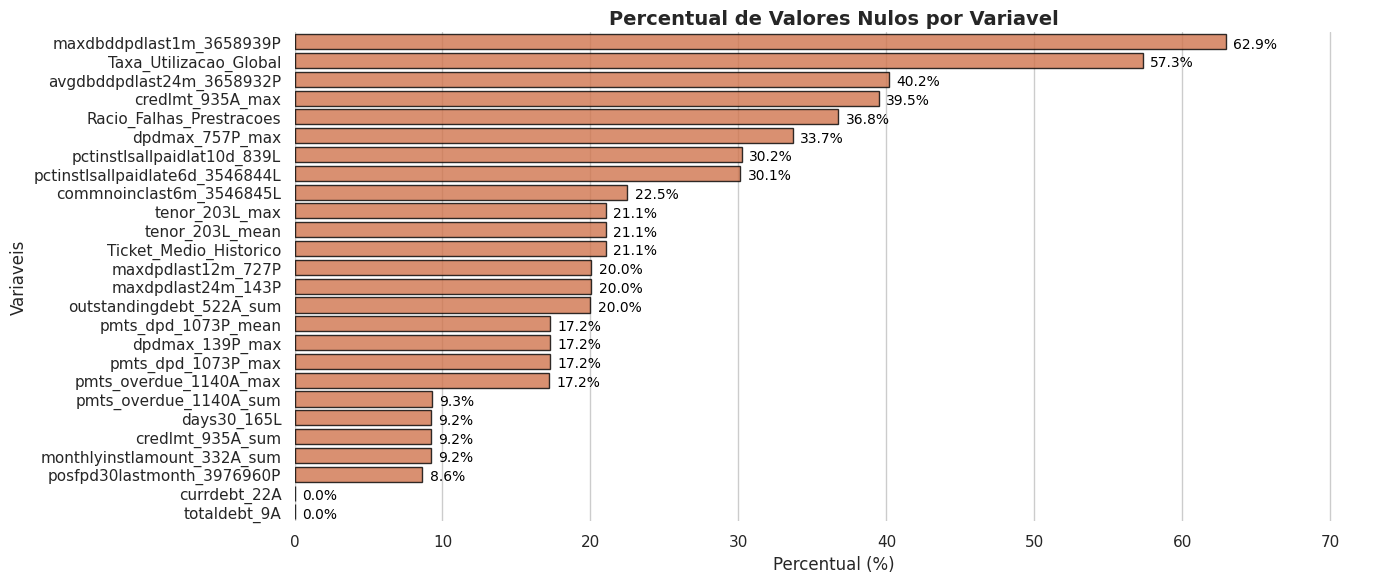

In [44]:
# 6.3 Verificar NaN remanescentes em colunas de DPD/histórico
dpd_cols = [c for c in df_master.columns if 'dpd' in c.lower() or 'overdue' in c.lower()]
if dpd_cols:
    print("NaN remanescentes em colunas de DPD/Overdue (preservados):")
    for c in dpd_cols[:15]:
        n_nulos = df_master[c].isna().sum()
        if n_nulos > 0:
            print(f"  {c}: {n_nulos:,} NaN ({n_nulos/len(df_master)*100:.1f}%)")

# Análise geral de nulos
df_nulos = analisar_valores_nulos(df_master, plotar=True, figsize=(14, 6))

### 7.4 Normalizando e Padronizando as variáveis

- Padronizando para evitar problemas de proporção nos algoritmos de árvore

- Uso do RobustScaler de modo a evitar influência de outliers

In [45]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import RobustScaler

# 1. Instanciar o escalonador
scaler = RobustScaler()

# 2. Definir as colunas que NÃO devem ser escalonadas
colunas_identificacao = ['case_id', 'date_decision', 'MONTH', 'WEEK_NUM', 'target']
colunas_binarias = [c for c in df_master.columns if 'Flag' in c or df_master[c].nunique() == 2]
colunas_temporais = ['Mes_do_Ano'] # O mês deve manter-se de 1 a 12 (ou ser tratado como categórico)

# Unir todas as exceções
excecoes = colunas_identificacao + colunas_binarias + colunas_temporais

# 3. Filtrar as variáveis numéricas contínuas para escalonamento
cols_to_scale = [c for c in df_master.columns if c not in excecoes and pd.api.types.is_numeric_dtype(df_master[c])]

print(f"Total de colunas selecionadas para escalonamento: {len(cols_to_scale)}")


# Forma segura de escalonar mantendo os NaNs (ideal para XGBoost/LightGBM que lidam com NaNs):
for col in cols_to_scale:
    # Máscara para localizar valores válidos (não nulos)
    mask = df_master[col].notna()
    
    # Aplica o fit_transform apenas sobre os valores que não são NaN
    if mask.sum() > 0:
        valores_transformados = scaler.fit_transform(df_master.loc[mask, [col]])
        df_master.loc[mask, col] = valores_transformados.flatten()

print("Escalonamento RobustScaler concluído com sucesso (os valores NaN originais foram preservados).")

Total de colunas selecionadas para escalonamento: 43
Escalonamento RobustScaler concluído com sucesso (os valores NaN originais foram preservados).


---

## 8.0 Diagnostico de Information Value (IV), Alta Correlação e Multicolinearidade (VIF)

Analise univariada do poder preditivo de cada feature em relacao ao target. O IV classifica a relevancia segundo as faixas de Siddiqi e funciona como excelente indicador de data leakage.

> * IV < 0.02: Inutil / Sem poder discriminatorio
> * 0.02 a 0.10: Fraco
> * 0.10 a 0.30: Medio
> * 0.30 a 0.50: Forte
> * 0.50: Suspeito (alerta de Data Leakage)

In [46]:
# =============================================================================
# 6.4 DIAGNÓSTICO UNIVARIADO VIA INFORMATION VALUE (IV)
# =============================================================================

def calcular_iv_dataset(df: pd.DataFrame, target_col: str, bins: int = 10) -> pd.DataFrame:
    """
    Calcula o Information Value (IV) para todas as features preditoras do DataFrame,
    classificando a relevância preditiva segundo as faixas de Siddiqi.
    """
    iv_resultados = []
    
    # Isola linhas válidas do target
    df_valid = df.dropna(subset=[target_col]).copy()
    total_bons = (df_valid[target_col] == 0).sum()
    total_maus = (df_valid[target_col] == 1).sum()
    eps = 1e-6 # Suavização contra divisão por zero / log de zero
    
    colunas_ignorar = ['case_id', 'date_decision', 'MONTH', 'WEEK_NUM', target_col]
    features = [c for c in df_valid.columns if c not in colunas_ignorar]
    
    for col in features:
        serie = df_valid[col]
        
        # Tratamento de nulos como categoria explícita ('Missing')
        if pd.api.types.is_numeric_dtype(serie):
            # Criação de faixas (quantis)
            try:
                categorias = pd.qcut(serie, q=bins, duplicates='drop').astype(str)
            except Exception:
                categorias = pd.cut(serie, bins=bins).astype(str)
            categorias = categorias.fillna('Missing')
        else:
            categorias = serie.fillna('Missing').astype(str)
            
        tabela = df_valid.groupby(categorias)[target_col].agg(
            total='count',
            maus='sum'
        ).reset_index()
        tabela['bons'] = tabela['total'] - tabela['maus']
        
        tabela['dist_bons'] = (tabela['bons'] + eps) / total_bons
        tabela['dist_maus'] = (tabela['maus'] + eps) / total_maus
        
        # WoE e IV
        tabela['woe'] = np.log(tabela['dist_bons'] / tabela['dist_maus'])
        iv_total = ((tabela['dist_bons'] - tabela['dist_maus']) * tabela['woe']).sum()
        
        # Classificação do IV
        if iv_total < 0.02:
            status = 'Sem Poder Preditivo'
        elif iv_total < 0.10:
            status = 'Poder Fraco'
        elif iv_total < 0.30:
            status = 'Poder Médio'
        elif iv_total <= 0.50:
            status = 'Poder Forte'
        else:
            status = 'Alerta: Suspeito / Leakage'
            
        iv_resultados.append({
            'Feature': col,
            'Information_Value': iv_total,
            'Diagnóstico': status
        })
        
    df_iv = pd.DataFrame(iv_resultados).sort_values(by='Information_Value', ascending=False).reset_index(drop=True)
    return df_iv

# Executando estritamente sobre a base histórica (evitando vazamento no OOT)
df_hist_analise = df_master[df_master['MONTH'] < 202007].copy()
relatorio_iv = calcular_iv_dataset(df_hist_analise, target_col='target')

print("=== TOP 15 FEATURES POR INFORMATION VALUE ===")
display(relatorio_iv.head(15))

print("\n=== FEATURES COM POTENCIAL DESCARTE (IV < 0.02) ===")
display(relatorio_iv[relatorio_iv['Information_Value'] < 0.02])

=== TOP 15 FEATURES POR INFORMATION VALUE ===


,Feature,Information_Value,Diagnóstico
0,pmts_dpd_1073P_mean,0.280482,Poder Médio
1,pmts_dpd_1073P_max,0.246357,Poder Médio
2,dpdmax_139P_max,0.245776,Poder Médio
3,dpdmax_757P_max,0.239532,Poder Médio
4,avgdbddpdlast24m_3658932P,0.237618,Poder Médio
5,pctinstlsallpaidlate6d_3546844L,0.224570,Poder Médio
6,pmts_overdue_1140A_max,0.222926,Poder Médio
7,pmts_overdue_1140A_sum,0.222764,Poder Médio
8,maxdpdlast24m_143P,0.214148,Poder Médio
9,pctinstlsallpaidlat10d_839L,0.201882,Poder Médio



=== FEATURES COM POTENCIAL DESCARTE (IV < 0.02) ===


,Feature,Information_Value,Diagnóstico
29,totaldebt_9A,1.199892e-02,Sem Poder Preditivo
30,currdebt_22A,1.197202e-02,Sem Poder Preditivo
31,annuity_780A,9.774270e-03,Sem Poder Preditivo
32,credlmt_935A_sum,8.451697e-03,Sem Poder Preditivo
33,Diferencial_Degradacao_Cliente,6.353238e-03,Sem Poder Preditivo
34,Taxa_Utilizacao_Global,5.783715e-03,Sem Poder Preditivo
35,posfpd30lastmonth_3976960P,3.399358e-03,Sem Poder Preditivo
36,applicationscnt_867L,3.198910e-03,Sem Poder Preditivo
37,monthlyinstlamount_332A_sum,2.961760e-03,Sem Poder Preditivo
38,Termometro_Busca_Bureau,2.617955e-03,Sem Poder Preditivo


> **Conclusoes do Diagnostico de Information Value (IV)**
>
> * **Validacao Anti-Leakage:** Nenhuma variavel apresentou IV suspeito (> 0.50). O preditor mais forte atingiu 0.28, garantindo uma base limpa de vazamentos do futuro.
> * **Supremacia do Historico (DPD):** O Top 10 e dominado por variaveis de atraso passado (ex: `pmts_dpd_1073P_mean`), comprovando que o melhor preditor de *default* e o comportamento de pagamento historico.
> * **Valores Absolutos vs. Racios:** Variaveis absolutas como divida total (`totaldebt_9A`) tiveram IV quase nulo (< 0.02). Elas serao mantidas nesta fase para que os algoritmos de arvores (LightGBM/CatBoost) possam encontrar relacoes nao-lineares cruzando-as com os racios de esforco.
> * **Decisao sobre Features Fracas:** Apesar de ~20 features com IV < 0.02, decidimos nao as descartar. A poda final sera feita via analise de *SHAP Values* na etapa de modelagem.

In [47]:
df_master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1526659 entries, 0 to 1526658
Data columns (total 66 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   case_id                          1526659 non-null  int32         
 1   date_decision                    1526659 non-null  datetime64[ns]
 2   MONTH                            1526659 non-null  int32         
 3   WEEK_NUM                         1526659 non-null  int16         
 4   target                           1526659 non-null  int8          
 5   maxdpdlast12m_727P               1220640 non-null  float64       
 6   maxdpdlast24m_143P               1220640 non-null  float64       
 7   avgdbddpdlast24m_3658932P        913457 non-null   float64       
 8   maxdbddpdlast1m_3658939P         565706 non-null   float64       
 9   pctinstlsallpaidlat10d_839L      1065297 non-null  float64       
 10  pctinstlsallpaidlate6d_3546844

>
> 65 colunas totais || 60 para predição

In [ ]:
#definindo o X_analise
colunas_ignorar = ['case_id', 'date_decision', 'MONTH', 'WEEK_NUM', 'target']
X_analise = df_master.drop(columns=[c for c in colunas_ignorar if c in df_master.columns])

### Análise de Correlação de Pearson entre os pares

In [ ]:
analisar_multicolinearidade_pares(df_master, limite=0.80)

#manter a com maior IV

--- Pares com Correlação > 0.8 ---
posfpd30lastmonth_3976960P & Flag_First_Payment_Default: 1.000
Flag_Has_RiskAssessment_940T & Flag_Thin_File: 1.000
pmtnum_8L_max & tenor_203L_max: 1.000
numrejects9m_859L & Frequencia_Rejeicoes_Mensal: 1.000
dpdmax_139P_max & pmts_dpd_1073P_max: 1.000
totaldebt_9A & currdebt_22A: 1.000
Flag_Has_RiskAssessment_302T & Flag_Thin_File: 1.000
Flag_Has_RiskAssessment_302T & Flag_Has_RiskAssessment_940T: 1.000
currdebt_22A & outstandingdebt_522A_sum: 0.998
totaldebt_9A & outstandingdebt_522A_sum: 0.998
applicationscnt_867L & Termometro_Busca_Bureau: 0.989
pctinstlsallpaidlat10d_839L & pctinstlsallpaidlate6d_3546844L: 0.965
dpdmax_139P_max & pmts_dpd_1073P_mean: 0.912
pmts_dpd_1073P_max & pmts_dpd_1073P_mean: 0.912
credlmt_935A_sum & credlmt_935A_max: 0.911
pmts_overdue_1140A_sum & pmts_overdue_1140A_max: 0.836
MONTH & WEEK_NUM: 0.835
maxdpdlast12m_727P & maxdpdlast24m_143P: 0.830
credamount_770A & annuity_780A: 0.820


> Devemos remover todas as `features` com **correlação altas**
>
> Apostaremos que as **features de cŕedito max/soma** etc possuem `interpretações diferentes` que serão melhor elucidados pelos algoritmos de árvore
>
> `vamos pegar as features de ddp_max pra cima e descartar`

In [ ]:
colunas_remover_colinearidade = [
    'posfpd30lastmonth_3976960P',    # Substituida por Flag_First_Payment_Default
    'Flag_Has_RiskAssessment_302T',  # Representada por Flag_Thin_File
    'Flag_Has_RiskAssessment_940T',  # Representada por Flag_Thin_File
    'pmtnum_8L_max',                 # Idêntica a tenor_203L_max
    'numrejects9m_859L',             # Substituida por Frequencia_Rejeicoes_Mensal
    'dpdmax_139P_max',               # Idêntica a pmts_dpd_1073P_max
    'totaldebt_9A',                  # Idêntica a currdebt_22A
    'outstandingdebt_522A_sum',      # Quase idêntica a currdebt_22A
    'applicationscnt_867L',          # Substituida por Termometro_Busca_Bureau
    'pctinstlsallpaidlat10d_839L',   # Pior IV em relação a pctinstlsallpaidlate6d
    'WEEK_NUM',                      # Variável de controlo, não preditiva
    'maxdpdlast24m_143P'             # Essencial para resolver o VIF infinito do Diferencial
]

df_master = df_master.drop(columns=colunas_remover_colinearidade, errors='ignore')
X_analise = X_analise.drop(columns=colunas_remover_colinearidade, errors='ignore')




### Análise VIF ( Multicolinearidade entre as colunas )

- Trabalhando um sample de 50k colunas 

In [ ]:

X_amostra = X_analise.sample(n=min(50000, len(X_analise)), random_state=42)

df_vif_resultados = analisar_vif(X_amostra, limite=10.0)


--- Variáveis com VIF > 10.0 (Alta Multicolinearidade) ---
credlmt_935A_max: 16.31
credlmt_935A_sum: 16.29
pmts_overdue_1140A_max: 11.39


> Vamos remover duas delas, como as de crédito possuem alta correlação, vamos remover a max e pmts_overdue
>
>

In [53]:
colunas_remover_colinearidade.extend([
    'credlmt_935A_max',        # Mantemos a 'sum' para o cálculo da Taxa de Utilização
    'pmts_overdue_1140A_sum'   # Mantemos a 'max' porque tem maior Information Value (IV)
])

# Reatribuição para garantir o drop
df_master = df_master.drop(columns=['credlmt_935A_max', 'pmts_overdue_1140A_sum'], errors='ignore')
X_analise = X_analise.drop(columns=['credlmt_935A_max', 'pmts_overdue_1140A_sum'], errors='ignore')

In [54]:
df_master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1526659 entries, 0 to 1526658
Data columns (total 52 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   case_id                          1526659 non-null  int32         
 1   date_decision                    1526659 non-null  datetime64[ns]
 2   MONTH                            1526659 non-null  int32         
 3   target                           1526659 non-null  int8          
 4   maxdpdlast12m_727P               1220640 non-null  float64       
 5   avgdbddpdlast24m_3658932P        913457 non-null   float64       
 6   maxdbddpdlast1m_3658939P         565706 non-null   float64       
 7   pctinstlsallpaidlate6d_3546844L  1066580 non-null  float64       
 8   numinstlswithdpd5_4187116L       1526659 non-null  float64       
 9   currdebt_22A                     1526655 non-null  float64       
 10  credamount_770A               

> **51 colunas totais** | **46 para predição**


---

## 9.0 Divisao Temporal e Exportacao (OOT e Split 70/30)

Separacao cronologica rigorosa para prevencao de *data leakage*. O corte OOT (`MONTH >= 202007`) isola os meses futuros. O split 70/30 estratificado no historico permite tuning de hiperparametros sem contaminar o OOT. O `StratifiedKFold` (5 folds) e configurado para consumo pelo `03_Modeling.ipynb`.

In [55]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# 9.1 Filtro Out-of-Time (OOT)
OOT_START = 202007

df_oot = df_master[df_master['MONTH'] >= OOT_START].copy()
df_hist = df_master[df_master['MONTH'] < OOT_START].copy()

print(f'OOT:  {df_oot.shape[0]:,} linhas | periodo {df_oot["MONTH"].min()} a {df_oot["MONTH"].max()} | default rate {df_oot["target"].mean()*100:.2f}%')
print(f'Hist: {df_hist.shape[0]:,} linhas | periodo {df_hist["MONTH"].min()} a {df_hist["MONTH"].max()} | default rate {df_hist["target"].mean()*100:.2f}%')

# 9.2 Split 70/30 estratificado no historico
df_train, df_test = train_test_split(
    df_hist,
    test_size=0.30,
    random_state=42,
    stratify=df_hist['target']
)

print(f'\nTrain: {df_train.shape[0]:,} linhas ({df_train.shape[0]/df_hist.shape[0]*100:.1f}%) | default rate {df_train["target"].mean()*100:.2f}%')
print(f'Test:  {df_test.shape[0]:,} linhas ({df_test.shape[0]/df_hist.shape[0]*100:.1f}%) | default rate {df_test["target"].mean()*100:.2f}%')

# 9.3 Stratified K-Fold (5 folds)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_train = df_train.drop(columns=['target'])
y_train = df_train['target']

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
    y_fold_val = y_train.iloc[val_idx]
    print(f'  Fold {fold_idx + 1}: {len(val_idx):,} amostras | default rate {y_fold_val.mean()*100:.2f}%')

print(f'\nStratifiedKFold configurado: {skf.get_n_splits()} folds, shuffle=True, random_state=42')

OOT:  150,240 linhas | periodo 202007 a 202010 | default rate 2.11%
Hist: 1,376,419 linhas | periodo 201901 a 202006 | default rate 3.26%

Train: 963,493 linhas (70.0%) | default rate 3.26%
Test:  412,926 linhas (30.0%) | default rate 3.26%
  Fold 1: 192,699 amostras | default rate 3.26%
  Fold 2: 192,699 amostras | default rate 3.26%
  Fold 3: 192,699 amostras | default rate 3.26%
  Fold 4: 192,698 amostras | default rate 3.26%
  Fold 5: 192,698 amostras | default rate 3.26%

StratifiedKFold configurado: 5 folds, shuffle=True, random_state=42


### Exportando os datasets TRAIN, TESTE e OOT  .pq

In [56]:
# 9.4 Exportacao dos conjuntos
output_dir = PROJECT_ROOT / 'data' / 'processed'
output_dir.mkdir(parents=True, exist_ok=True)

df_oot.to_parquet(output_dir / 'df_oot.parquet', index=False, engine='pyarrow')
df_train.to_parquet(output_dir / 'df_train.parquet', index=False, engine='pyarrow')
df_test.to_parquet(output_dir / 'df_test.parquet', index=False, engine='pyarrow')
df_master.to_parquet(output_dir / 'master_table.parquet', index=False, engine='pyarrow')

for f in ['df_oot.parquet', 'df_train.parquet', 'df_test.parquet', 'master_table.parquet']:
    fpath = output_dir / f
    size_mb = fpath.stat().st_size / (1024**2)
    print(f'  {f}: {size_mb:.1f} MB')

print(f'\nExportacao concluida em: {output_dir}')

  df_oot.parquet: 7.7 MB
  df_train.parquet: 46.8 MB
  df_test.parquet: 21.2 MB
  master_table.parquet: 67.0 MB

Exportacao concluida em: /content/Projeto_06/data/processed


> **Proximo passo:** o `03_Modeling.ipynb` consumira `df_train.parquet` para treino com validacao cruzada (5 folds estratificados), `df_test.parquet` para avaliacao intra-periodo, e `df_oot.parquet` para avaliacao de estabilidade temporal.

---

## 10.0 Dicionario Tecnico das Features Final

Documentacao completa de todas as variaveis da Master Table, organizada por origem e tipo.

### 10.1 Importadas Diretamente (Depth 0) -- 20 features

Variaveis brutas que vieram intocadas do merge original, sem transformacao adicional.

> **Historico de Atrasos (DPD)**
> * `maxdpdlast12m_727P` -- Maior atraso em dias nos ultimos 12 meses.
> * `avgdbddpdlast24m_3658932P` -- Media de dias de atraso/antecipacao nos ultimos 2 anos.
> * `maxdbddpdlast1m_3658939P` -- Atraso maximo em dias no ultimo mes.
> * `pctinstlsallpaidlate6d_3546844L` -- Percentagem de prestacoes pagas com 6+ dias de atraso.
> * `numinstlswithdpd5_4187116L` -- Contagem de prestacoes com 5+ dias de atraso.
>
> **Endividamento e Montantes**
> * `currdebt_22A` -- Divida atual (saldo devedor em aberto).
> * `credamount_770A` -- Montante de credito solicitado.
> * `annuity_780A` -- Valor da prestacao mensal proposta.
>
> **Rendimento e Emprego**
> * `commnoinclast6m_3546845L` -- Alerta de ausencia de rendimento nos ultimos 6 meses.
> * `clientscnt_887L` -- Numero de clientes partilhando o mesmo telefone/empregador (alerta de fraude).
>
> **Rejeicoes e Aplicacoes**
> * `applicationscnt_629L` -- Aplicacoes com o mesmo empregador nos ultimos 7 dias.
> * `days30_165L` -- Consultas ao bureau nos ultimos 30 dias.
> * `days180_256L` -- Consultas (hard pulls) ao bureau nos ultimos 180 dias.
>
> **Contratos Anteriores**
> * `numinstunpaidmaxest_4493212L` -- Maximo de prestacoes nao pagas num contrato.
> * `numinstpaid_4499208L` -- Total de prestacoes pagas com sucesso.
> * `numactiverelcontr_750L` -- Contratos de credito revogavel (cartoes) ativos.

### 10.2 Agregacoes (Depth 1/2) -- 16 features

Variaveis achatadas via agregacoes de historico (`max`, `sum`, `mean`) por `case_id`.

> * `dpdmax_757P_max` -- Pior atraso em contratos encerrados (agregacao `max`).
> * `pmts_dpd_1073P_max` / `pmts_dpd_1073P_mean` -- Pico e media historica de DPD nos pagamentos.
> * `credlmt_935A_sum` -- Soma de limites de credito (usada no calculo da Taxa de Utilizacao).
> * `outstandingdebt_522A_sum` -- Soma da divida pendente de pedidos anteriores.
> * `monthlyinstlamount_332A_sum` -- Soma das prestacoes mensais ativas.
> * `pmts_overdue_1140A_max` -- Pico de montantes em atraso.
> * `pmtnum_8L_sum` -- Volume total de pagamentos efetuados.
> * `tenor_203L_max` / `tenor_203L_mean` -- Prazo maximo e medio dos emprestimos.
> * `credacc_transactions_402L_sum` -- Volume financeiro total de transacoes em contas de credito.

### 10.3 Shadow Features -- 1 feature

Flags criadas exclusivamente a partir da ausencia de dados (padroes de nulos).

> * **`Flag_Thin_File`** -- `1` se o cliente nao possui nenhum dos dois scores de bureau (`riskassesment_302T` e `riskassesment_940T`). Representa o perfil "cliente desconhecido pelo mercado", que carrega premio de risco estrutural.

### 10.4 Features Derivadas e Regras de Negocio (13 features)

Variaveis criadas via cruzamento de colunas originais, agrupadas por eixo preditivo. Todos os racios utilizam `np.where` para preservar valores reais, deixando `NaN` onde o divisor for zero (tratamento nativo dos algoritmos de Boosting).

> **Racios de Alavancagem e Esforco**
> * `Racio_Anuidade_Credito` = `np.where(credamount_770A > 0, annuity_780A / credamount_770A, NaN)`. Peso da amortizacao sobre o credito total.
> * `Taxa_Utilizacao_Global` = `np.where(credlmt_935A_sum > 0, currdebt_22A / credlmt_935A_sum, NaN)`. Saturacao das linhas de credito.
> * `Ticket_Medio_Historico` = `np.where(pmtnum_8L_sum > 0, monthlyinstlamount_332A_sum / pmtnum_8L_sum, NaN)`. Valor medio que o cliente suporta pagar mensalmente.
> * `Racio_Falhas_Prestracoes` = `numinstlswithdpd5_4187116L / (numinstpaid_4499208L + 1)`. Taxa historica de falhas nos pagamentos.
> * `Diferencial_Degradacao_Cliente` = `maxdpdlast12m_727P - maxdpdlast24m_143P`. Evolucao da disciplina financeira.
>
> **Dinamica de Atrasos (DPD Momentum)**
> * `Aceleracao_Atraso_Ativo` = `actualdpd_943P - maxdpdlast24m_143P`. Degradacao aguda se positivo.
> * `Flag_Pico_Atraso_Recente` = `1` se `actualdpd_943P > mediana historica`.
>
> **Intensidade e Anomalias de Busca**
> * `Frequencia_Rejeicoes_Mensal` = `numrejects9m_859L / 9`. Taxa mensal de portas fechadas.
> * `Termometro_Busca_Bureau` = `applicationscnt_867L / (applicationscnt_629L + 1)`. Distorcoes nos pedidos.
>
> **Flags de Risco Critico**
> * `Flag_First_Payment_Default` = `1` se `posfpd30lastmonth_3976960P > 0`. Forte indicios de fraude planeada (*never pay*).
> * `Flag_Sobre_Endividamento_Aberto` = `1` se `currdebt_22A > 0.8 * credlmt_935A_sum`.
>
> **Macroeconomico e Sazonalidade**
> * `Mes_do_Ano_2` a `Mes_do_Ano_12` -- Dummies sazonais via One-Hot Encoding (`drop_first=True`, janeiro como categoria de referencia). A variavel original `Mes_do_Ano` foi convertida em `category` antes do OHE.
> * `Flag_Pandemia` = `1` se `MONTH >= 202003`. Choque COVID-19.

### 10.5 Features Descartadas no Pipeline

Colunas removidas durante o processamento, com a justificativa tecnica.

> **Descartadas por excesso de nulos (>70%):**
> * `riskassesment_302T` (96.5% nulos) -- Substituida pela shadow feature `Flag_Has_RiskAssessment_302T`.
> * `riskassesment_940T` (96.5% nulos) -- Substituida pela shadow feature `Flag_Has_RiskAssessment_940T`.
> * `forquarter_462L` (97.6% nulos) -- Esparsidade extrema sem sinal recuperavel.
> * `amount_1115A_sum` (97.6% nulos) -- Agregacao Depth 1/2 com cobertura insuficiente.
> * `amount_1115A_mean` (98.3% nulos) -- Idem.
> * `credacc_transactions_402L_mean` (83.4% nulos) -- Media de transacoes com cobertura muito baixa.
>
> **Descartadas por ruido:**
> * `lastrejectreasonclient_4145040M` -- Codigo anonimizado de altissima cardinalidade. Nao agrega poder discriminatorio e gera dimensionalidade espuria.
>
> **Descartadas por Multicolinearidade Severa (>0.95):**
> * `posfpd30lastmonth_3976960P` -- Correlacao perfeita (1.000) com `Flag_First_Payment_Default`. Redundante.
> * `Flag_Has_RiskAssessment_302T` -- Correlacao perfeita (1.000) com `Flag_Thin_File`. Substituida.
> * `Flag_Has_RiskAssessment_940T` -- Correlacao perfeita (1.000) com `Flag_Thin_File`. Substituida.
> * `pmtnum_8L_max` -- Correlacao perfeita (1.000) com `tenor_203L_max`. Redundante.
> * `numrejects9m_859L` -- Correlacao perfeita (1.000) com `Frequencia_Rejeicoes_Mensal`. Substituida pelo racio normalizado.
> * `dpdmax_139P_max` -- Correlacao perfeita (1.000) com `pmts_dpd_1073P_max`. Redundante.
> * `totaldebt_9A` -- Correlacao perfeita (1.000) com `currdebt_22A`. Redundante.
> * `outstandingdebt_522A_sum` -- Correlacao quase-perfeita (0.998) com `currdebt_22A`. Redundante.
> * `applicationscnt_867L` -- Correlacao de 0.989 com `Termometro_Busca_Bureau`. Substituida pelo racio.
> * `pctinstlsallpaidlat10d_839L` -- Correlacao de 0.965 com `pctinstlsallpaidlate6d_3546844L`. Pior IV.
> * `WEEK_NUM` -- Variavel de controlo temporal, nao preditiva. Correlacao de 0.835 com `MONTH`.
> * `maxdpdlast24m_143P` -- Correlacao de 0.830 com `maxdpdlast12m_727P`. Essencial para resolver VIF infinito do `Diferencial_Degradacao_Cliente`.
> * `credlmt_935A_max` -- VIF = 16.31 (>10). Mantida a versao `sum` para o calculo da Taxa de Utilizacao.
> * `pmts_overdue_1140A_sum` -- VIF > 10. Mantida a versao `max` por ter maior Information Value.